# Stock Price Analysis with Pandas

### Apple (`AAPL`) vs Microsoft (`MSFT`) · 2019-01-01 to 2026-09-01

This notebook is a reproducible walkthrough of a practical Pandas time-series workflow. It downloads daily **open, high, low, close, adjusted close, and volume (OHLCV)** observations with `yfinance`, puts dates on the index, changes frequency with `.resample()`, and calculates trend indicators with `.rolling()`.

**Questions**

1. How did each company's closing price change over the sample?
2. What do daily observations look like at weekly and monthly frequencies?
3. How do 20-session and 200-session moving averages describe short- and long-term trends?
4. How do the companies' trading volumes compare?

> **Educational use only.** This descriptive analysis is not financial advice, and past market behavior does not predict future results. Yahoo Finance data can be delayed, revised, or adjusted differently from other providers.

## 1. Setup

The sample dates are fixed so that reruns are comparable. `yfinance` treats `end` as **exclusive**, so `2026-09-01` requests observations through the final trading day before September 1.

Set the environment variable `STOCK_DATA_OFFLINE=1` before launching Jupyter to skip the network request and use the documented snapshots in `data/`.

In [1]:
from pathlib import Path
import os
import warnings

from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
import pandas as pd
import yfinance as yf

# Analysis configuration
TICKERS = {
    "AAPL": "Apple",
    "MSFT": "Microsoft",
}
START_DATE = "2019-01-01"
END_DATE = "2026-09-01"  # yfinance's end date is exclusive
OFFLINE = os.getenv("STOCK_DATA_OFFLINE", "0") == "1"

# Locate data whether Jupyter starts in the repository root or this folder.
project_candidates = [Path.cwd(), Path.cwd() / "stock-price-analysis"]
PROJECT_DIR = next(
    (path for path in project_candidates if (path / "data").is_dir()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Could not find stock-price-analysis/data. Start Jupyter from the project folder "
        "or the repository root."
    )
DATA_DIR = PROJECT_DIR / "data"

COLORS = {"AAPL": "#2563EB", "MSFT": "#D97706"}
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update(
    {
        "figure.figsize": (12, 5.5),
        "figure.dpi": 110,
        "axes.titleweight": "bold",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "legend.frameon": False,
    }
)

print(f"Pandas {pd.__version__} | yfinance {yf.__version__}")
print(f"Mode: {'offline snapshots' if OFFLINE else 'Yahoo Finance with snapshot fallback'}")

Pandas 2.3.3 | yfinance 0.2.66
Mode: offline snapshots


## 2. Download and prepare daily data

`yf.download()` usually returns a `DatetimeIndex`. To make the index operation explicit and consistent with CSV input, `prepare_market_data()` first brings the date back into a column, parses it with `pd.to_datetime()`, and then calls `.set_index("Date")`.

`auto_adjust=False` retains both `Close` and `Adj Close`. This notebook charts `Close` to satisfy the project question; adjusted close remains available for total-return extensions.

In [2]:
REQUIRED_COLUMNS = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]


def prepare_market_data(raw: pd.DataFrame) -> pd.DataFrame:
    """Return validated OHLCV data with a sorted, unique DatetimeIndex."""
    data = raw.copy()

    # A one-ticker yfinance response can still have MultiIndex columns in some releases.
    if isinstance(data.columns, pd.MultiIndex):
        ticker_levels = set(TICKERS).intersection(data.columns.get_level_values(-1))
        if len(ticker_levels) == 1:
            data = data.xs(next(iter(ticker_levels)), axis=1, level=-1)
        else:
            data.columns = data.columns.get_level_values(0)

    data = data.reset_index()
    if "Date" not in data.columns:
        # CSV and yfinance inputs both place the date first after reset_index().
        data = data.rename(columns={data.columns[0]: "Date"})

    missing = set(REQUIRED_COLUMNS).difference(data.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    data["Date"] = (
        pd.to_datetime(data["Date"], errors="coerce", utc=True)
        .dt.tz_localize(None)
        .dt.normalize()
    )
    for column in REQUIRED_COLUMNS:
        data[column] = pd.to_numeric(data[column], errors="coerce")

    data = (
        data.dropna(subset=["Date", "Open", "High", "Low", "Close", "Volume"])
        .drop_duplicates(subset="Date", keep="last")
        .sort_values("Date")
        .set_index("Date")
    )
    data.index.name = "Date"
    return data[REQUIRED_COLUMNS]


def download_or_load(ticker: str) -> tuple[pd.DataFrame, str, str]:
    """Download a ticker with yfinance, falling back to its bundled CSV snapshot."""
    fallback_reason = "offline mode requested"

    if not OFFLINE:
        try:
            downloaded = yf.download(
                ticker,
                start=START_DATE,
                end=END_DATE,
                interval="1d",
                auto_adjust=False,
                actions=False,
                progress=False,
                threads=False,
                multi_level_index=False,
                timeout=15,
            )
            if not downloaded.empty:
                return prepare_market_data(downloaded), "Yahoo Finance", "live download"
            fallback_reason = "Yahoo Finance returned no rows"
        except Exception as error:  # network/provider errors should not block the lesson
            fallback_reason = f"{type(error).__name__}: {error}"

    snapshot_path = DATA_DIR / f"{ticker}.csv"
    if not snapshot_path.exists():
        raise FileNotFoundError(
            f"No data was downloaded and fallback snapshot is missing: {snapshot_path}"
        )

    if not OFFLINE:
        warnings.warn(
            f"{ticker}: using bundled snapshot because {fallback_reason}.",
            RuntimeWarning,
            stacklevel=2,
        )
    snapshot = pd.read_csv(snapshot_path)
    return prepare_market_data(snapshot), "Bundled snapshot", fallback_reason

In [3]:
stock_data: dict[str, pd.DataFrame] = {}
source_records = []

for ticker, company in TICKERS.items():
    frame, source, note = download_or_load(ticker)
    stock_data[ticker] = frame
    source_records.append(
        {
            "Ticker": ticker,
            "Company": company,
            "Source": source,
            "First date": frame.index.min().date(),
            "Last date": frame.index.max().date(),
            "Rows": len(frame),
            "Note": note,
        }
    )

source_summary = pd.DataFrame(source_records).set_index("Ticker")
display(source_summary)

,Company,Source,First date,Last date,Rows,Note
Ticker,,,,,,
AAPL,Apple,Bundled snapshot,2019-01-02,2026-08-28,1925,offline mode requested
MSFT,Microsoft,Bundled snapshot,2019-01-02,2026-08-28,1925,offline mode requested


### Confirm the date index and inspect the observations

A `DatetimeIndex` is what makes label slicing, `.resample()`, and time-aware plotting work naturally. The checks below also guard against unsorted dates, duplicate sessions, impossible negative prices, and negative volume.

In [4]:
quality_records = []
for ticker, frame in stock_data.items():
    assert isinstance(frame.index, pd.DatetimeIndex)
    assert frame.index.is_monotonic_increasing
    assert frame.index.is_unique
    assert (frame[["Open", "High", "Low", "Close"]] > 0).all().all()
    assert (frame["Volume"] >= 0).all()

    quality_records.append(
        {
            "Ticker": ticker,
            "Index type": type(frame.index).__name__,
            "Sorted": frame.index.is_monotonic_increasing,
            "Duplicate dates": int(frame.index.duplicated().sum()),
            "Missing values": int(frame.isna().sum().sum()),
            "Trading sessions": len(frame),
        }
    )

quality_report = pd.DataFrame(quality_records).set_index("Ticker")
display(quality_report)

display(
    pd.concat(
        {ticker: frame.head(3) for ticker, frame in stock_data.items()},
        names=["Ticker", "Date"],
    ).round(2)
)

,Index type,Sorted,Duplicate dates,Missing values,Trading sessions
Ticker,,,,,
AAPL,DatetimeIndex,True,0,0,1925
MSFT,DatetimeIndex,True,0,0,1925


Open    High    Low   Close  Adj Close     Volume
Ticker Date                                                           
AAPL   2019-01-02   38.72   39.71  38.56   39.48      37.44  148158800
       2019-01-03   35.99   36.43  35.50   35.55      33.71  365248800
       2019-01-04   36.13   37.14  35.95   37.06      35.15  234428400
MSFT   2019-01-02   99.55  101.75  98.94  101.12      94.02   35329300
       2019-01-03  100.10  100.19  97.20   97.40      90.56   42579100
       2019-01-04   99.72  102.51  98.93  101.93      94.77   44060600

## 3. Closing prices over time

The first line chart compares nominal closing prices. Because a share of Apple is not the same unit as a share of Microsoft, the next chart rebases both series to 100 on their first available session. The rebased view compares **relative price change**, not dollars per share.

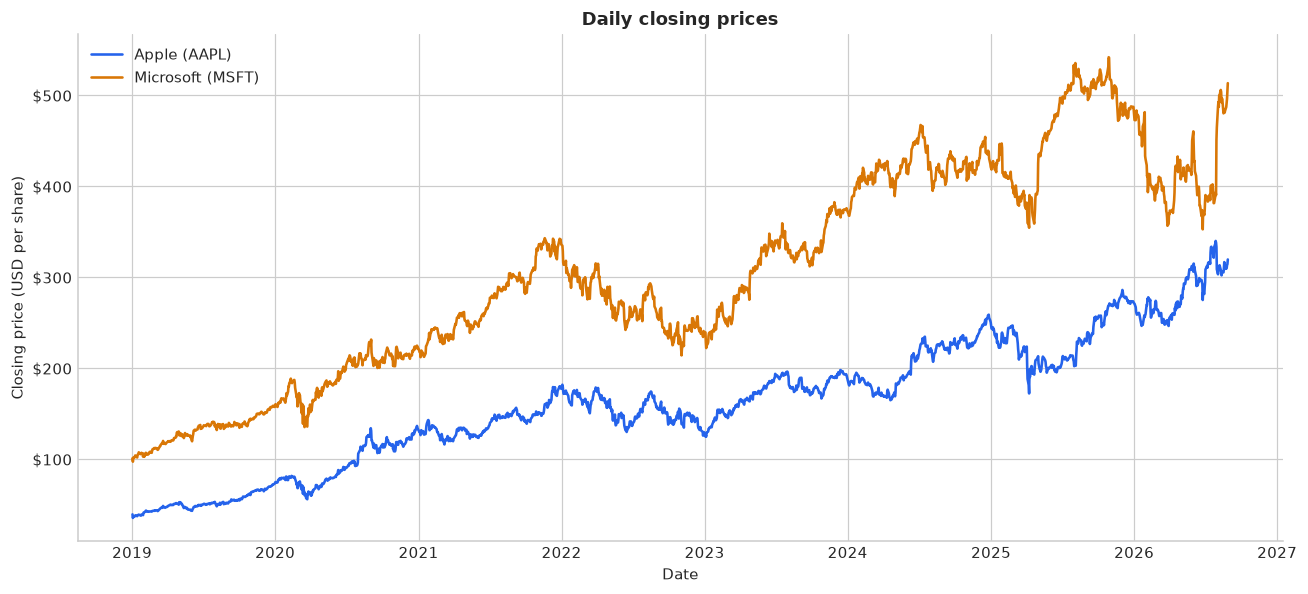

In [5]:
close_prices = pd.concat(
    {ticker: frame["Close"] for ticker, frame in stock_data.items()},
    axis=1,
)
close_prices.columns.name = "Ticker"

fig, ax = plt.subplots()
for ticker in TICKERS:
    ax.plot(
        close_prices.index,
        close_prices[ticker],
        label=f"{TICKERS[ticker]} ({ticker})",
        color=COLORS[ticker],
        linewidth=1.7,
    )
ax.set(
    title="Daily closing prices",
    xlabel="Date",
    ylabel="Closing price (USD per share)",
)
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"${value:,.0f}"))
ax.legend()
plt.tight_layout()
plt.show()

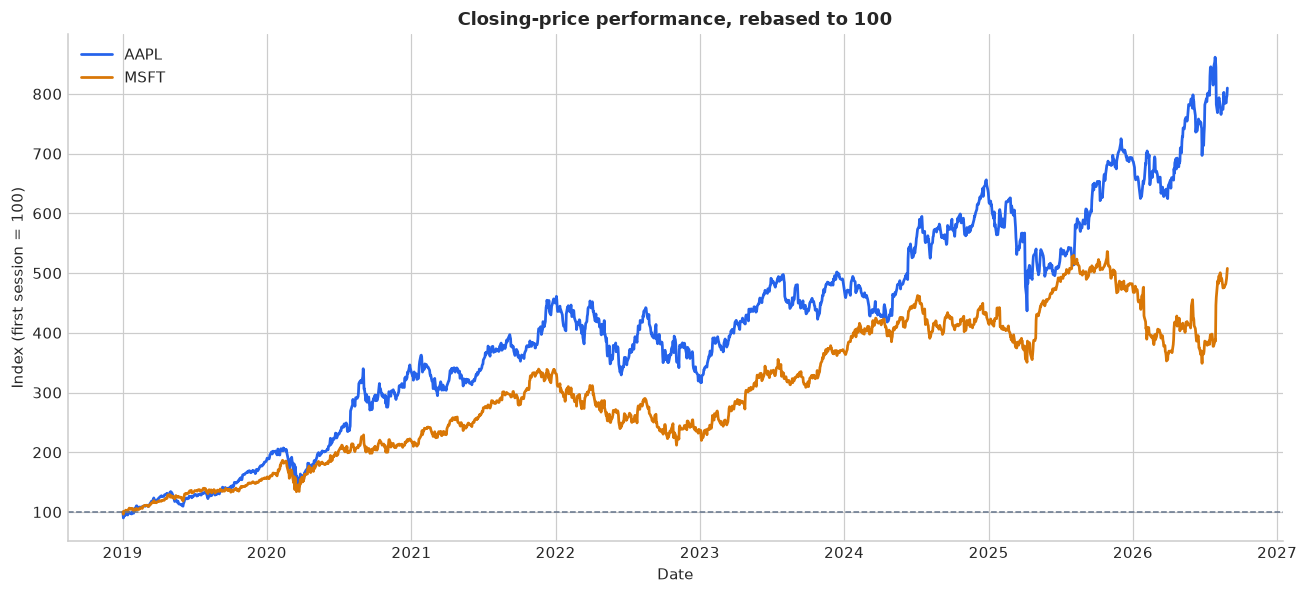

In [6]:
normalized_close = close_prices.apply(
    lambda series: series / series.dropna().iloc[0] * 100
)

fig, ax = plt.subplots()
for ticker in TICKERS:
    ax.plot(
        normalized_close.index,
        normalized_close[ticker],
        label=ticker,
        color=COLORS[ticker],
        linewidth=1.8,
    )
ax.axhline(100, color="#64748B", linewidth=1, linestyle="--")
ax.set(
    title="Closing-price performance, rebased to 100",
    xlabel="Date",
    ylabel="Index (first session = 100)",
)
ax.legend()
plt.tight_layout()
plt.show()

## 4. Resample daily observations to weekly and monthly bars

Resampling must respect what each field means:

- **Open** → first observation in the period
- **High** → maximum
- **Low** → minimum
- **Close / Adj Close** → last observation
- **Volume** → sum

A weekly frequency of `W-FRI` labels periods on Friday. `ME` means calendar month-end. Market holidays can mean the actual final observation occurred before its label.

In [7]:
OHLCV_AGGREGATION = {
    "Open": "first",
    "High": "max",
    "Low": "min",
    "Close": "last",
    "Adj Close": "last",
    "Volume": "sum",
}

weekly_data = {
    ticker: frame.resample("W-FRI").agg(OHLCV_AGGREGATION).dropna(subset=["Close"])
    for ticker, frame in stock_data.items()
}
monthly_data = {
    ticker: frame.resample("ME").agg(OHLCV_AGGREGATION).dropna(subset=["Close"])
    for ticker, frame in stock_data.items()
}

frequency_summary = pd.DataFrame(
    {
        "Daily rows": {ticker: len(frame) for ticker, frame in stock_data.items()},
        "Weekly rows": {ticker: len(frame) for ticker, frame in weekly_data.items()},
        "Monthly rows": {ticker: len(frame) for ticker, frame in monthly_data.items()},
    }
)
display(frequency_summary)

print("Latest weekly bars")
display(
    pd.concat(
        {ticker: frame.tail(3) for ticker, frame in weekly_data.items()},
        names=["Ticker", "Week ending"],
    ).round(2)
)
print("Latest monthly bars")
display(
    pd.concat(
        {ticker: frame.tail(3) for ticker, frame in monthly_data.items()},
        names=["Ticker", "Month ending"],
    ).round(2)
)

,Daily rows,Weekly rows,Monthly rows
AAPL,1925,400,92
MSFT,1925,400,92


Latest weekly bars


Open    High     Low   Close  Adj Close     Volume
Ticker Week ending                                                      
AAPL   2026-08-14   306.83  309.97  300.57  305.93     305.93  192525700
       2026-08-21   306.21  320.28  302.94  309.35     309.35  229935400
       2026-08-28   311.47  322.37  308.21  319.70     319.70  165636500
MSFT   2026-08-14   503.44  513.73  491.52  495.40     494.47  122514000
       2026-08-21   490.14  492.66  477.15  483.24     483.24  116216900
       2026-08-28   483.21  517.78  481.86  513.53     513.53  115404800

Latest monthly bars


Open    High     Low   Close  Adj Close      Volume
Ticker Month ending                                                       
AAPL   2026-06-30    309.63  317.40  273.75  289.36     289.11  1401170100
       2026-07-31    293.44  344.57  289.20  308.91     308.64  1198861200
       2026-08-31    309.58  322.37  300.57  319.70     319.70   861166500
MSFT   2026-06-30    464.84  466.32  349.20  373.02     372.32  1017814300
       2026-07-31    380.83  466.84  373.35  464.72     463.85   815118000
       2026-08-31    476.13  517.78  475.00  513.53     513.53   570029900

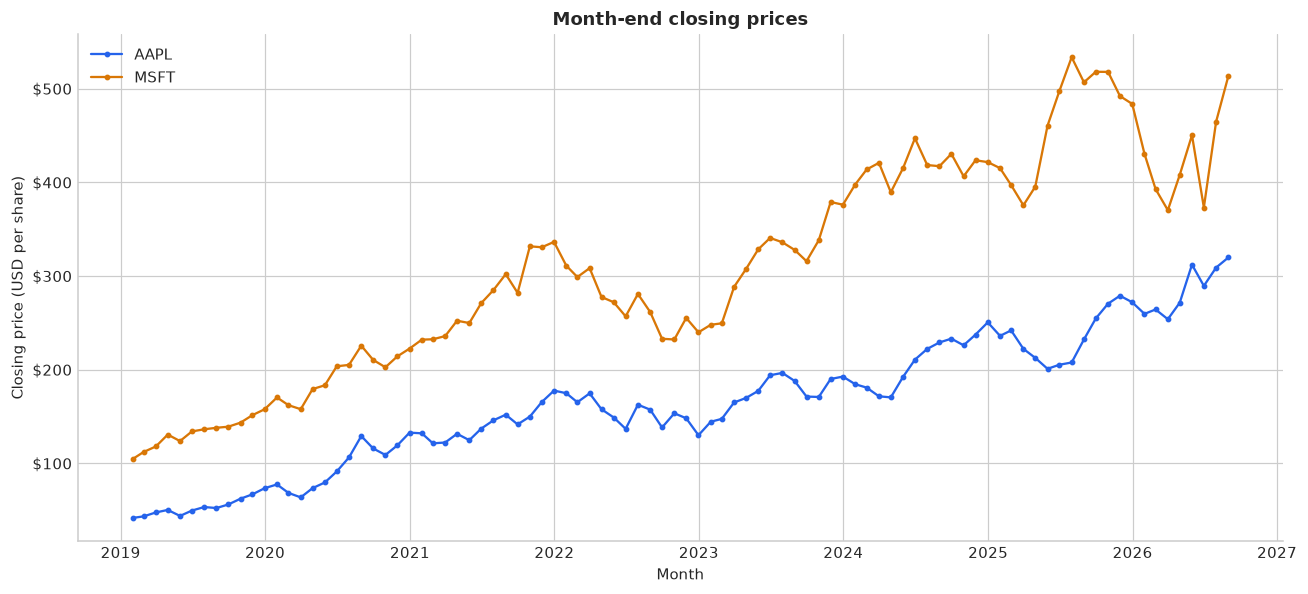

In [8]:
fig, ax = plt.subplots()
for ticker, frame in monthly_data.items():
    ax.plot(
        frame.index,
        frame["Close"],
        label=ticker,
        color=COLORS[ticker],
        marker="o",
        markersize=2.8,
        linewidth=1.5,
    )
ax.set(
    title="Month-end closing prices",
    xlabel="Month",
    ylabel="Closing price (USD per share)",
)
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"${value:,.0f}"))
ax.legend()
plt.tight_layout()
plt.show()

## 5. Calculate 20-session and 200-session moving averages

`.rolling(window=...)` operates on rows here, so these are trading-session windows rather than calendar-day windows. A 20-session average approximates one trading month; a 200-session average is a commonly used long-horizon trend measure.

`min_periods` equals the window length to avoid presenting partial-window values as full moving averages. These are **lagging descriptive indicators**, not forecasts.

In [9]:
analysis_data: dict[str, pd.DataFrame] = {}
for ticker, frame in stock_data.items():
    analysis = frame.copy()
    analysis["MA_20"] = analysis["Close"].rolling(
        window=20, min_periods=20
    ).mean()
    analysis["MA_200"] = analysis["Close"].rolling(
        window=200, min_periods=200
    ).mean()
    analysis_data[ticker] = analysis

moving_average_counts = pd.DataFrame(
    {
        "20-day MA observations": {
            ticker: int(frame["MA_20"].notna().sum())
            for ticker, frame in analysis_data.items()
        },
        "200-day MA observations": {
            ticker: int(frame["MA_200"].notna().sum())
            for ticker, frame in analysis_data.items()
        },
    }
)
display(moving_average_counts)

,20-day MA observations,200-day MA observations
AAPL,1906,1726
MSFT,1906,1726


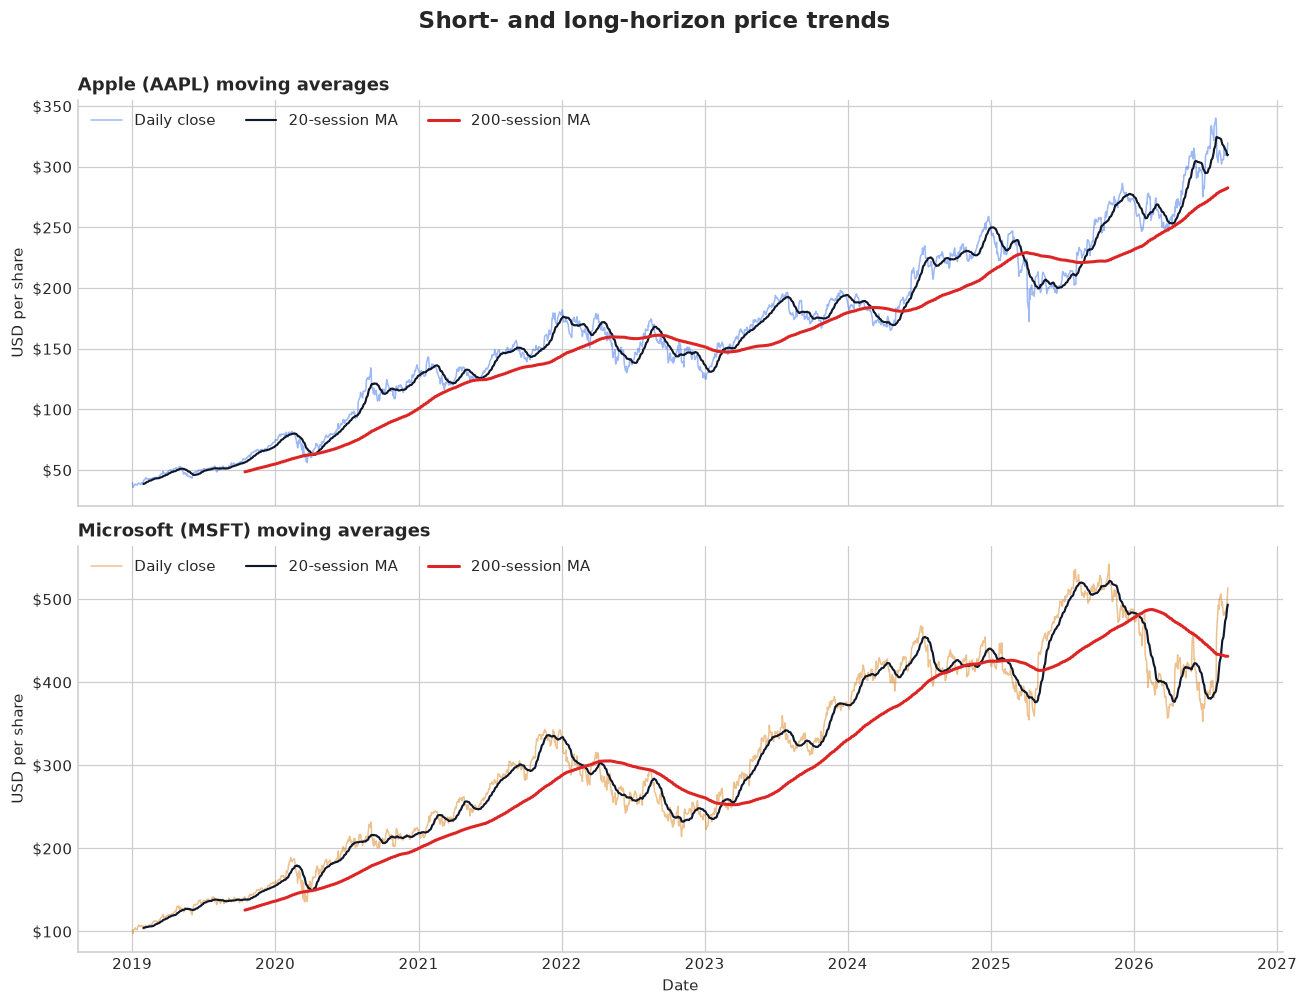

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

for ax, (ticker, frame) in zip(axes, analysis_data.items()):
    ax.plot(
        frame.index,
        frame["Close"],
        color=COLORS[ticker],
        alpha=0.45,
        linewidth=1,
        label="Daily close",
    )
    ax.plot(frame.index, frame["MA_20"], color="#0F172A", linewidth=1.4, label="20-session MA")
    ax.plot(frame.index, frame["MA_200"], color="#DC2626", linewidth=2, label="200-session MA")
    ax.set_title(f"{TICKERS[ticker]} ({ticker}) moving averages", loc="left")
    ax.set_ylabel("USD per share")
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"${value:,.0f}"))
    ax.legend(ncols=3, loc="upper left")

axes[-1].set_xlabel("Date")
fig.suptitle("Short- and long-horizon price trends", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

## 6. Compare trading volume

Daily volume is noisy, so the time-series chart uses a 20-session rolling mean. The bar chart compares each ticker's mean and median daily number of shares traded over the complete sample. Volume is shown in shares, not dollars; share prices and shares outstanding differ between companies.

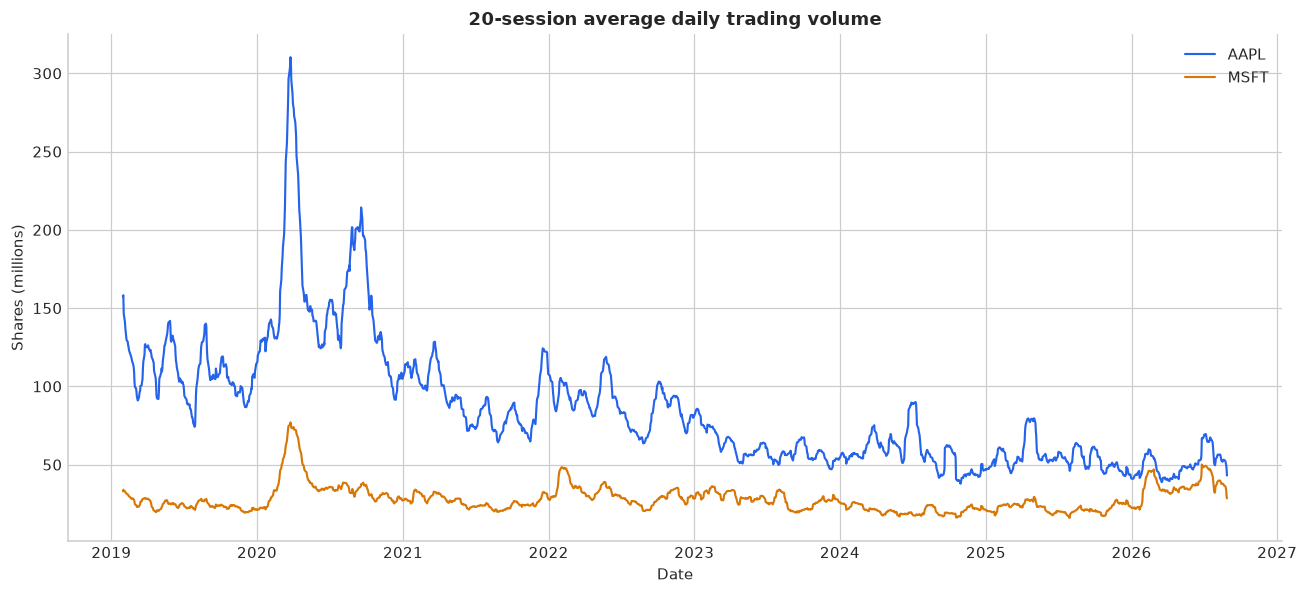

In [11]:
volume = pd.concat(
    {ticker: frame["Volume"] for ticker, frame in stock_data.items()},
    axis=1,
)
volume.columns.name = "Ticker"
volume_20 = volume.rolling(window=20, min_periods=20).mean() / 1_000_000

fig, ax = plt.subplots()
for ticker in TICKERS:
    ax.plot(
        volume_20.index,
        volume_20[ticker],
        label=ticker,
        color=COLORS[ticker],
        linewidth=1.4,
    )
ax.set(
    title="20-session average daily trading volume",
    xlabel="Date",
    ylabel="Shares (millions)",
)
ax.legend()
plt.tight_layout()
plt.show()

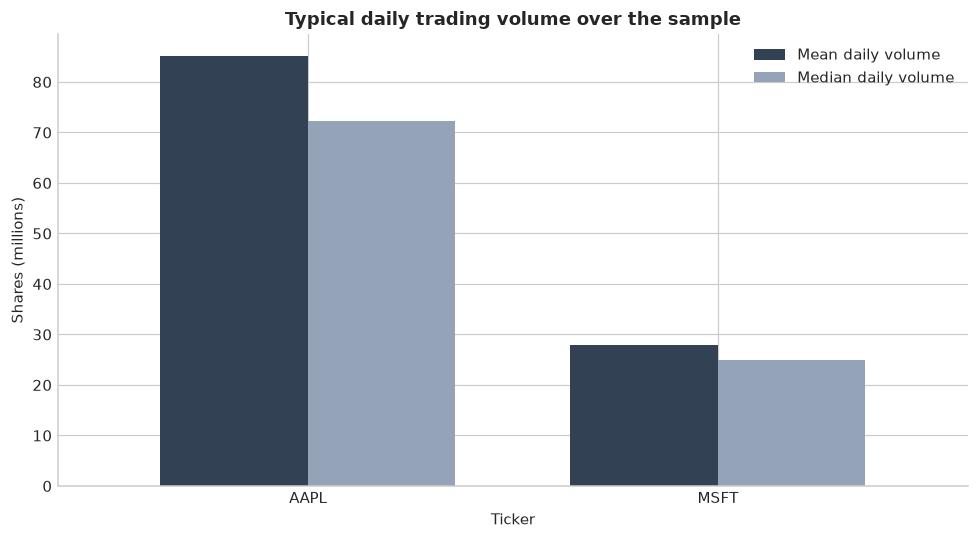

,Mean daily volume,Median daily volume
Ticker,,
AAPL,85.20,72.37
MSFT,27.96,24.95


In [12]:
volume_summary = pd.DataFrame(
    {
        "Mean daily volume": volume.mean() / 1_000_000,
        "Median daily volume": volume.median() / 1_000_000,
    }
)

ax = volume_summary.plot.bar(
    color=["#334155", "#94A3B8"],
    figsize=(9, 5),
    rot=0,
    width=0.72,
)
ax.set(
    title="Typical daily trading volume over the sample",
    xlabel="Ticker",
    ylabel="Shares (millions)",
)
ax.legend(title=None)
plt.tight_layout()
plt.show()

display(volume_summary.round(2))

## 7. Descriptive performance summary

The statistics below use closing-price changes and therefore are not a complete investor total-return calculation. Annualized volatility assumes 252 trading sessions. Maximum drawdown is the largest peak-to-trough decline observed in this sample. CAGR is annualized from the first and last close.

In [13]:
summary_records = []
for ticker, frame in stock_data.items():
    close = frame["Close"].dropna()
    daily_return = close.pct_change().dropna()
    years = (close.index[-1] - close.index[0]).days / 365.25
    drawdown = close.div(close.cummax()).sub(1)

    summary_records.append(
        {
            "Ticker": ticker,
            "First close": close.iloc[0],
            "Last close": close.iloc[-1],
            "Total price return": close.iloc[-1] / close.iloc[0] - 1,
            "CAGR": (close.iloc[-1] / close.iloc[0]) ** (1 / years) - 1,
            "Annualized volatility": daily_return.std() * (252 ** 0.5),
            "Maximum drawdown": drawdown.min(),
            "Average daily volume": frame["Volume"].mean(),
        }
    )

performance_summary = pd.DataFrame(summary_records).set_index("Ticker")
display(
    performance_summary.style.format(
        {
            "First close": "${:,.2f}",
            "Last close": "${:,.2f}",
            "Total price return": "{:.1%}",
            "CAGR": "{:.1%}",
            "Annualized volatility": "{:.1%}",
            "Maximum drawdown": "{:.1%}",
            "Average daily volume": "{:,.0f}",
        }
    )
)

,First close,Last close,Total price return,CAGR,Annualized volatility,Maximum drawdown,Average daily volume
Ticker,,,,,,,
AAPL,$39.48,$319.70,709.8%,31.4%,30.8%,-33.4%,"85,203,245"
MSFT,$101.12,$513.53,407.8%,23.7%,29.3%,-37.6%,"27,956,948"


In [14]:
return_leader = performance_summary["Total price return"].idxmax()
volume_leader = performance_summary["Average daily volume"].idxmax()

print(
    f"• {return_leader} had the larger closing-price gain in this fixed sample "
    f"({performance_summary.loc[return_leader, 'Total price return']:.1%})."
)
print(
    f"• {volume_leader} had the higher mean daily share volume "
    f"({performance_summary.loc[volume_leader, 'Average daily volume'] / 1_000_000:,.1f} million shares)."
)
for ticker, frame in analysis_data.items():
    latest = frame.dropna(subset=["MA_200"]).iloc[-1]
    relationship = "above" if latest["Close"] > latest["MA_200"] else "below"
    print(
        f"• On {frame.index[-1].date()}, {ticker} closed {relationship} its 200-session "
        f"moving average (${latest['Close']:,.2f} vs ${latest['MA_200']:,.2f})."
    )

• AAPL had the larger closing-price gain in this fixed sample (709.8%).
• AAPL had the higher mean daily share volume (85.2 million shares).
• On 2026-08-28, AAPL closed above its 200-session moving average ($319.70 vs $282.60).
• On 2026-08-28, MSFT closed above its 200-session moving average ($513.53 vs $431.18).


## 8. Takeaways and limitations

- A proper `DatetimeIndex` unlocks chronological slicing, frequency conversion, rolling windows, and automatic date axes.
- Daily prices preserve detail; weekly and monthly OHLCV bars reduce noise while maintaining each field's financial meaning.
- The 20-session average responds faster than the 200-session average, while both necessarily lag the market.
- Mean volume above median volume indicates that high-volume sessions pull the average upward; a rolling mean makes changes in typical activity easier to compare.
- Nominal share prices should not be interpreted as company value. A normalized series is better for relative price change, while market capitalization requires shares outstanding.
- Closing-price returns omit dividends. `Adj Close` can support a follow-up adjusted-return analysis, but provider adjustment methods should be documented.
- This two-stock historical sample has survivorship and selection bias and does not establish a trading strategy.

### Possible extensions

Calculate daily return correlations, drawdowns, rolling volatility, and adjusted-close total returns; add a benchmark such as the S&P 500; or parameterize the ticker list and date range.